In [1]:
import pennylane as qml
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from functools import reduce
###
import numpy as np


# Added to silence some warnings.
jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).
# jax.config.update("jax_platform_name", "cpu") # Force cpu.
# jax.config.update('jax_dynamic_shapes', True)


jax.print_environment_info()

jax:    0.4.28
jaxlib: 0.4.28
numpy:  2.3.1
python: 3.12.10 (main, May 12 2025, 15:49:11) [Clang 17.0.0 (clang-1700.0.13.3)]
jax.devices (1 total, 1 local): [CpuDevice(id=0)]
process_count: 1
platform: uname_result(system='Darwin', node='papaya.local', release='24.5.0', version='Darwin Kernel Version 24.5.0: Tue Apr 22 19:53:27 PDT 2025; root:xnu-11417.121.6~2/RELEASE_ARM64_T6041', machine='arm64')



In [2]:
key = jax.random.PRNGKey(42)

In [3]:
def is_unitary(m: jnp.ndarray):
    return jnp.allclose(jnp.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: jnp.ndarray):
    return jnp.allclose(m, m.T.conj())

def is_sorted(x: jnp.ndarray, ascending: bool = True):
    """Checks if input array elements are in sorted order (ascending by default)."""
    x = jnp.array(x)
    if ascending:
        return bool(jnp.all(x[:-1] <= x[1:]))
    else:
        return bool(jnp.all(x[:-1] >= x[1:]))

def is_positive_definite(x: jnp.ndarray):
    """Checks if input matrix is positive definite, meaning all eigenvalues are non-zero."""
    return jnp.all(jnp.linalg.eigvals(x) > 0)

def softmax(x: jnp.ndarray, axis=None):
    y = jnp.exp(x - jnp.max(x, axis=axis, keepdims=True)) # Stabilize to prevent overflow.
    return y / jnp.sum(y, axis=axis, keepdims=True)

In [4]:
def prepare_actions(
    wires_actions: list[int],
    action_probs_vec: jnp.ndarray, # shape (n_actions,),
    normalize: bool = False,
    ):
    # n_actions = action_probs_vec.shape[0]
    
    # d_actions = int(jnp.round(jnp.log2(n_actions)).item())
    # # print(f"{jnp.log2(n_actions)=}")
    # # print(f"{jnp.log2(n_actions).astype(jnp.int64)=}")
    # # print(f"{int(jnp.round(jnp.log2(n_actions)).item())=}")
    # # print(f"{jnp.log2(n_actions).item()=}")
    # # print(f"{d_actions=}")
    # if n_actions != 2**d_actions:
    #     raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(jnp.sqrt(action_probs_vec), wires=wires_actions, normalize=normalize) # Must normalize since inputs are probability vectors.


def prepare_returns(
    wires_actions: list[int],
    wires_returns: list[int],
    returns_probs_matrix: jnp.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    n_actions, n_returns = returns_probs_matrix.shape
    
    # d_returns = int(jnp.round(jnp.log2(n_returns)).item())
    # # print(f"{d_returns=}")
    # if n_returns != 2**d_returns:
    #     raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(jnp.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)

In [5]:
from pennylane.ops.channel import Channel
from pennylane.operation import AnyWires
from pennylane.wires import WiresLike, Wires
class NonTracePreservingQubitChannel(Channel):
    num_wires = AnyWires
    grad_method = None

    def __init__(self, K_list, wires: WiresLike, id=None):
        wires = Wires(wires)
        super().__init__(*K_list, wires=wires, id=id)

        # check all Kraus matrices are square matrices
        if any(K.shape[0] != K.shape[1] for K in K_list):
            raise ValueError(
                "Only channels with the same input and output Hilbert space dimensions can be applied."
            )

        # check all Kraus matrices have the same shape
        if any(K.shape != K_list[0].shape for K in K_list):
            raise ValueError("All Kraus matrices must have the same shape.")

        # check the dimension of all Kraus matrices are valid
        if any(K.ndim != 2 for K in K_list):
            raise ValueError(
                "Dimension of all Kraus matrices must be (2**num_wires, 2**num_wires)."
            )

        # # check that the channel represents a trace-preserving map
        # if not any(np.is_abstract(K) for K in K_list):
        #     K_arr = np.array(K_list)
        #     Kraus_sum = np.einsum("ajk,ajl->kl", K_arr.conj(), K_arr)
        #     if not np.allclose(Kraus_sum, np.eye(K_list[0].shape[0])):
        #         raise ValueError("Only trace preserving channels can be applied.")

    def _flatten(self):
        return (self.data,), (self.wires, ())

    # pylint: disable=arguments-differ, unused-argument
    @classmethod
    def _primitive_bind_call(cls, K_list, wires: WiresLike, id=None):
        wires = Wires(wires)
        return super()._primitive_bind_call(*K_list, wires=wires)

    @staticmethod
    def compute_kraus_matrices(*kraus_matrices):  # pylint:disable=arguments-differ
        """Kraus matrices representing the QubitChannel channel.

        Args:
            *K_list (list[array[complex]]): list of Kraus matrices

        Returns:
            list (array): list of Kraus matrices

        **Example**

        >>> K_list = qml.PhaseFlip(0.5, wires=0).kraus_matrices()
        >>> res = qml.QubitChannel.compute_kraus_matrices(K_list)
        >>> all(np.allclose(r, k) for r, k  in zip(res, K_list))
        True
        """
        return list(kraus_matrices)
        

def circuit(
    d_actions: int,
    d_returns: int,
    action_probs_vec: jax.typing.ArrayLike,
    returns_probs_matrix: jax.typing.ArrayLike,
    U_returns_atoms: jax.typing.ArrayLike,
    n_reuploads: int,
    ):
    """Distributional returns comparison circuit.
    Two sets of qubits: actions, and return-atoms. Kicks back expectation of return-atoms to action distribution, which in turn weights the action distribution by the relative expected return.
    """
    wires = list(range(d_actions + d_returns + 1))
    wires_actions = wires[:d_actions]
    wires_returns = wires[d_actions:-1]
    wires_control = wires[-1] # Extra wire at the end to know which channel was applied.
    
    # Prepare initial action distribution, and return-atom distribution for each action.
    prepare_actions(wires_actions=wires_actions, action_probs_vec=action_probs_vec, normalize=True)
    prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True)
    
    # Apply the (non-unitary) return-atom-value operation.
    # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    ########
    # I = jnp.eye(2,2) # Identity for 1 qubit.
    # X = jnp.array([[0,1],[1,0]]) # NOT gate.
    # Q_I = jnp.kron(jnp.eye(*U_returns_atoms.shape), X.conj().T) - jnp.kron(U_returns_atoms.conj().T @ U_returns_atoms, X.conj().T) # Q \kron I.
    # Q_X = Q_I @ jnp.kron(jnp.eye(*U_returns_atoms.shape), X) # M = Q \kron X = I - U.conj().T @ U.
    # qml.QubitChannel([jnp.kron(U_returns_atoms, I), jnp.sqrt(Q_X)], wires=[*wires_returns, wires_control])
    ########
    I = jnp.eye(2,2) # Identity for 1 qubit.
    X = jnp.array([[0,1],[1,0]]) # NOT gate.
    Z = jnp.array([[1,0],[0,-1]]) # Z gate.
    # K = jnp.kron(U_returns_atoms, I) # U \kron I.
    K = jnp.kron(U_returns_atoms, Z) # U \kron I.
    Q_I = jnp.sqrt(jnp.eye(*K.shape) - K.conj().T @ K) @ jnp.kron(jnp.eye(*U_returns_atoms.shape), X.conj().T)
    Q_X = Q_I @ jnp.kron(jnp.eye(*U_returns_atoms.shape), X) # Q_X = sqrt(M) = sqrt(I - U.conj().T @ U).
    qml.QubitChannel([K, Q_X], wires=[*wires_returns, wires_control])
    # qml.QubitChannel([K, Q_X], wires=[*wires_returns, wires_control])
    # qml.QubitChannel([K, Q_X], wires=[*wires_returns, wires_control])
    # qml.QubitChannel([K, Q_X], wires=[*wires_returns, wires_control])
    # qml.QubitChannel([jnp.sqrt(0.9)*K, jnp.sqrt(0.1)*Q_X], wires=[*wires_returns, wires_control])
    ########
    # qml.QubitChannel(jnp.array([U_returns_atoms]), wires=wires_returns)
    ########
    # M = jnp.eye(*U_returns_atoms.shape) - U_returns_atoms.conj() @ U_returns_atoms
    # qml.QubitChannel([U_returns_atoms, jnp.sqrt(M)], wires=wires_returns)
    # NonTracePreservingQubitChannel([U_returns_atoms, M], wires=wires_returns)
    ########
    # Operator to skew input before applying U_returns_atoms.
    # https://quantumcomputing.stackexchange.com/a/39371
    # X = jnp.linalg.inv(jnp.sqrt(U_returns_atoms)) # Inverse square-root.
    # qml.QubitChannel([U_returns_atoms @ X], wires=wires_returns)
    # qml.QubitUnitary(U_returns_atoms @ X, wires=wires_returns, unitary_check=False)
    ########
    # M = jnp.eye(*U_returns_atoms.shape) - U_returns_atoms.conj() @ U_returns_atoms
    # qml.QubitChannel([U_returns_atoms, jnp.sqrt(M)], wires=wires_returns)
    # qml.QubitChannel([U_returns_atoms, 0*jnp.sqrt(M)], wires=wires_returns)
    ########
    
    # # Measure the return-atom qubits to collapse their state, then reset to zero.
    # for w in wires_returns:
    #     qml.measure(wires=w, reset=True)
    
    # # Re-upload initial return-atom distribution for every action, apply the return-atom-value operation, and then measure/reset to collapse the return-atom qubits.
    # # n_returns = int(2**d_returns)
    # # n_actions = int(2**d_actions)
    # # n_reuploads = n_returns
    # # n_reuploads = n_returns*2
    # # n_reuploads = n_actions
    # # n_reuploads = d_returns
    # # n_reuploads = 0
    # for _ in range(n_reuploads):
    #     prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix, normalize=True)
    #     # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    #     ########
    #     qml.QubitChannel([K, Q_X], wires=[*wires_returns, wires_control])
    #     ########
    #     # qml.QubitChannel([jnp.kron(U_returns_atoms, I), jnp.sqrt(Q_X)], wires=[*wires_returns, wires_control])
    #     ########
    #     # qml.QubitChannel(jnp.array([U_returns_atoms]), wires=wires_returns)
    #     ########
    #     # qml.QubitChannel([U_returns_atoms, jnp.sqrt(M)], wires=wires_returns)
    #     # NonTracePreservingQubitChannel([U_returns_atoms, M], wires=wires_returns)
    #     ########
    #     # qml.QubitChannel([U_returns_atoms @ X], wires=wires_returns)
    #     # qml.QubitUnitary(U_returns_atoms @ X, wires=wires_returns, unitary_check=False)
    #     ########
    #     # qml.QubitChannel([U_returns_atoms, jnp.sqrt(M)], wires=wires_returns)d
    #     # qml.QubitChannel([U_returns_atoms, 0*jnp.sqrt(M)], wires=wires_returns)
    #     ########
    #     for w in wires_returns:
    #         qml.measure(wires=w, reset=True)
    
    return qml.probs(wires=wires_actions), qml.probs(wires=wires_returns), qml.probs(wires=wires_control), qml.expval(qml.PauliZ(wires_control)), qml.expval(reduce(lambda x,y: x@y, [qml.PauliZ(w) for w in wires_returns]))

In [6]:
key

Array([ 0, 42], dtype=uint32)

In [7]:
from functools import partial
@partial(jax.jit, static_argnames=['d_actions', 'd_returns', 'n_reuploads', 'shots', 'name', 'diff_method'])
def circuit_jit(
    key: jax.typing.ArrayLike,
    d_actions: int,
    d_returns: int,
    action_probs_vec: jax.typing.ArrayLike,
    returns_probs_matrix: jax.typing.ArrayLike,
    U_returns_atoms: jax.typing.ArrayLike,
    n_reuploads: int,
    shots: int | None = None,
    name: str = "default.qubit",
    diff_method: str | None = None,
    ):
    
    # Device construction inside `jax.jit`.
    dev = qml.device(name=name, shots=shots, seed=key)
    # qnode = qml.QNode(func=circuit, device=dev, interface="jax", diff_method=diff_method)
    qnode = qml.QNode(func=circuit, device=dev, interface="jax-jit", diff_method=diff_method)
    return qnode(
        d_actions=d_actions,
        d_returns=d_returns,
        action_probs_vec=action_probs_vec,
        returns_probs_matrix=returns_probs_matrix,
        U_returns_atoms=U_returns_atoms,
        n_reuploads=n_reuploads,
        )

In [8]:
d_actions = 2
d_returns = 2
n_actions = 2**d_actions
n_returns = 2**d_returns

print(f"{n_actions=}")
print(f"{n_returns=}")
print(f"{d_actions=}")
print(f"{d_returns=}")

n_actions=4
n_returns=4
d_actions=2
d_returns=2


In [9]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([2465931498, 3679230171], dtype=uint32)


In [10]:
returns_probs_matrix = jnp.abs(jax.random.normal(key, shape=(n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / jnp.sum(returns_probs_matrix, axis=1, keepdims=True)  # Normalize to make it a probability vector (sums to 1).

In [11]:
returns_probs_matrix

Array([[0.38601083, 0.23808814, 0.06226631, 0.31363473],
       [0.12288614, 0.56582956, 0.3049449 , 0.0063394 ],
       [0.21809667, 0.09059835, 0.38746745, 0.30383753],
       [0.48089602, 0.2733837 , 0.03808362, 0.20763667]], dtype=float64)

In [12]:
# returns_atoms_values_original = jnp.array([-1,0,1,100])
# returns_atoms_values_original = jnp.array([-10,0,1,100])
# returns_atoms_values_original = jnp.array([-100,-10,0,1])
# returns_atoms_values_original = jnp.array([-1,0,1,10])
# returns_atoms_values_original = jnp.array([-1,0,1,2])
returns_atoms_values_original = jnp.array([float(i)+1 for i in range(n_returns)])/n_returns*4 # Steep exponential.
# returns_atoms_values_original = np.array([float(i)+1 for i in range(n_returns)])/n_returns*10 # Steep exponential.
returns_atoms_values_original_normalized = softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = jax.nn.softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2) / (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2).sum() # Turn into probability distribution with some adjustment to ensure that the minimum is close to zero but not exactly zero.

# returns_atoms_values_original_normalized = returns_atoms_values_original_normalized/returns_atoms_values_original_normalized.max() # Ensure maximum value is 1.

returns_atoms_values = returns_atoms_values_original_normalized.copy()
returns_atoms_values = jnp.sqrt(returns_atoms_values)
# returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) # values - epsilon (epsilon is zero).
# returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) - 3.6e-2 # values - epsilon.
# returns_atoms_values = returns_atoms_values / returns_atoms_values.max() # Ensure maximum value is 1.

U_returns_atoms = jnp.diag(returns_atoms_values)

# U_returns_atoms = U_returns_atoms / U_returns_atoms.max() # Ensure maximum value is 1.

In [13]:
returns_atoms_values_original_normalized

Array([0.0320586 , 0.08714432, 0.23688282, 0.64391426], dtype=float64)

In [14]:
returns_atoms_values

Array([0.17904916, 0.29520217, 0.48670609, 0.80244268], dtype=float64)

In [15]:
U_returns_atoms

Array([[0.17904916, 0.        , 0.        , 0.        ],
       [0.        , 0.29520217, 0.        , 0.        ],
       [0.        , 0.        , 0.48670609, 0.        ],
       [0.        , 0.        , 0.        , 0.80244268]], dtype=float64)

In [16]:
is_positive_definite(U_returns_atoms)

Array(True, dtype=bool)

In [17]:
# Turn trace non-increasing map into one that is trace preserving.
# https://quantumcomputing.stackexchange.com/questions/27705/can-one-turn-a-non-trace-preserving-map-into-one-that-is-trace-preserving
M = jnp.eye(*U_returns_atoms.shape) - U_returns_atoms.conj() @ U_returns_atoms
M

Array([[0.9679414 , 0.        , 0.        , 0.        ],
       [0.        , 0.91285568, 0.        , 0.        ],
       [0.        , 0.        , 0.76311718, 0.        ],
       [0.        , 0.        , 0.        , 0.35608574]], dtype=float64)

In [18]:
M + U_returns_atoms.conj()@U_returns_atoms

Array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]], dtype=float64)

In [19]:
# Operator to skew input before applying U_returns_atoms.
# https://quantumcomputing.stackexchange.com/a/39371
X = jnp.linalg.inv(jnp.sqrt(U_returns_atoms)) # Inverse square-root.
print(f"{X=}")

X=Array([[2.36327277, 0.        , 0.        , 0.        ],
       [0.        , 1.84051868, 0.        , 0.        ],
       [0.        , 0.        , 1.43339739, 0.        ],
       [0.        , 0.        , 0.        , 1.11633101]], dtype=float64)


In [20]:
is_positive_definite(X)

Array(True, dtype=bool)

In [21]:
U_returns_atoms @ X

Array([[0.42314201, 0.        , 0.        , 0.        ],
       [0.        , 0.5433251 , 0.        , 0.        ],
       [0.        , 0.        , 0.69764324, 0.        ],
       [0.        , 0.        , 0.        , 0.89579165]], dtype=float64)

In [22]:
U_returns_atoms.conj().T @ X.conj().T @ X @ U_returns_atoms

Array([[0.17904916, 0.        , 0.        , 0.        ],
       [0.        , 0.29520217, 0.        , 0.        ],
       [0.        , 0.        , 0.48670609, 0.        ],
       [0.        , 0.        , 0.        , 0.80244268]], dtype=float64)

In [23]:
is_hermitian(U_returns_atoms @ X)

Array(True, dtype=bool)

In [24]:
action_probs_vec_original = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec_original = jnp.array(action_probs_vec_original) # Convert to jax array for vectorization.
action_probs_vec = action_probs_vec_original.copy() # Preserve the original.

In [25]:
# Number of times to re-upload return-atoms.
n_reuploads = d_returns
# n_reuploads = d_returns*2

In [26]:
# Print the circuit to ensure it is what we expect.
print(qml.draw(circuit)(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, n_reuploads))

0: ─╭|Ψ⟩─╭Select───────────────┤ ╭Probs       
1: ─╰|Ψ⟩─├Select───────────────┤ ╰Probs       
2: ──────├Select─╭QubitChannel─┤ ╭Probs ╭<Z@Z>
3: ──────╰Select─├QubitChannel─┤ ╰Probs ╰<Z@Z>
4: ──────────────╰QubitChannel─┤  Probs  <Z>  


In [27]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([3164236999, 3984487275], dtype=uint32)


In [ ]:
# name = "default.qubit"
name = "default.mixed"
shots = None # Exact numerical simulation.
# shots = 1
# shots = 5
# shots = 10
# shots = 100
# shots = 1000
# diff_method = None # Fails with JAX and 'default.mixed' device.
diff_method = "backprop"
# diff_method = "adjoint"
# diff_method = "parameter-shift"
# (probs_actions, probs_returns) = circuit_jit(
#     key=key,
#     d_actions=d_actions,
#     d_returns=d_returns,
#     action_probs_vec=action_probs_vec,
#     returns_probs_matrix=returns_probs_matrix,
#     U_returns_atoms=U_returns_atoms,
#     n_reuploads=n_reuploads,
#     name=name,
#     shots=shots,
#     diff_method=diff_method,
#     )
(probs_actions, probs_returns, probs_control, expval_control, expval_returns) = qml.QNode(func=circuit, device=qml.device("default.mixed", shots=shots, seed=key), interface='jax')(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, n_reuploads)
# (probs_actions, probs_returns) = qml.QNode(func=circuit, device=qml.device("default.mixed", shots=shots))(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, n_reuploads)

print(f"{probs_actions=}")
print(f"{probs_returns=}")
print(f"{probs_control=}")
print(f"{expval_returns=}")
print(f"{expval_control=}")
print(f"{U_returns_atoms=}")

probs_actions=Array([0.25, 0.25, 0.25, 0.25], dtype=float64)
probs_returns=Array([0.30197241, 0.29197494, 0.19819057, 0.20786208], dtype=float64)
probs_control=Array([1., 0.], dtype=float64)
expval_returns=Array(0.01966899, dtype=float64)
expval_control=Array(1., dtype=float64)
U_returns_atoms=Array([[0.17904916, 0.        , 0.        , 0.        ],
       [0.        , 0.29520217, 0.        , 0.        ],
       [0.        , 0.        , 0.48670609, 0.        ],
       [0.        , 0.        , 0.        , 0.80244268]], dtype=float64)


In [29]:
# probs_actions = probs_actions / probs_actions.sum() # Normalize.

In [30]:
from collections import namedtuple
ActionRank = namedtuple("ActionRank", ["action", "rank"])

### Rank actions from high-to-low based on their weighted expected return.

action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_manual_compute = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_manual_compute)) # [(action_index, rank), ...]
print(f"action_rank_manual_compute={[a for a,r in action_rank_manual_compute]}")

### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_circuit_probs = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_circuit_probs)) # [(action_index, rank), ...]
print(f"action_rank_circuit_probs={[a for a,r in action_rank_circuit_probs]}")

action_rank_manual_compute=[2, 0, 1, 3]
action_rank_circuit_probs=[2, 0, 3, 1]


Text(0.5, 1.0, 'Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = False\nTop 3 rank match = False (jumbled match? False)\nTop 1 rank match = True')

<Figure size 640x480 with 0 Axes>

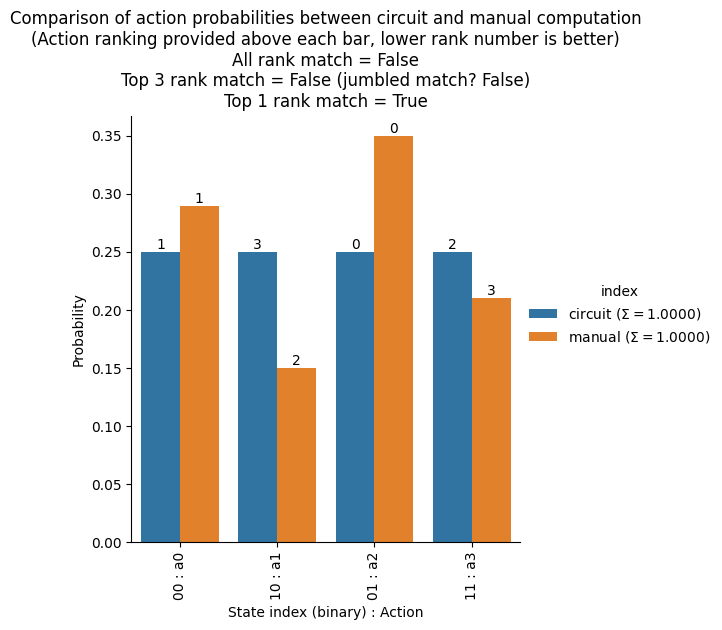

In [31]:
### To make visual comparison easier, plot action probabilities from quantum circuit and manual computation together on same chart.

# Compute manual returns probabilities.
# y = returns_probs_matrix @ returns_atoms_values_original
y = returns_probs_matrix @ returns_atoms_values_original_normalized
y /= y.sum()

# Plot circuit action probabilities and manual computation action probabilities together.
df = pd.DataFrame(np.array([probs_actions, y]), columns=[f"a{i}" for i in range(n_actions)], index=[f"circuit ($\\Sigma = {probs_actions.sum():.4f}$)", f"manual ($\\Sigma = {y.sum():.4f}$)"])
df = df.reset_index()
df = df.melt(id_vars='index')

plt.figure()
g = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax = g.facet_axis(0, 0)
for idx, (container, actionrank) in enumerate(zip(ax.containers, [action_rank_circuit_probs, action_rank_manual_compute])):
    # labels = [f"{v.get_height():.4f}" for v in container]
    actionrank = sorted(actionrank, key=lambda ar: ar.action)
    labels = [f"{actionrank[j].rank}" for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, label_type='edge')
g.set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
g.set_xlabels("State index (binary) : Action")
g.set_ylabels("Probability")
plt.title(f"Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = {action_rank_manual_compute == action_rank_circuit_probs}\nTop 3 rank match = {action_rank_manual_compute[:3] == action_rank_circuit_probs[:3]} (jumbled match? {set(a for a, r in action_rank_manual_compute[:3]) == set(a for a, r in action_rank_circuit_probs[:3])})\nTop 1 rank match = {action_rank_manual_compute[0] == action_rank_circuit_probs[0]}")

---

In [32]:
U_returns_atoms.shape

(4, 4)

In [33]:
X.shape

(4, 4)

In [34]:
X

Array([[2.36327277, 0.        , 0.        , 0.        ],
       [0.        , 1.84051868, 0.        , 0.        ],
       [0.        , 0.        , 1.43339739, 0.        ],
       [0.        , 0.        , 0.        , 1.11633101]], dtype=float64)

In [35]:
M = jnp.eye(*U_returns_atoms.shape) - U_returns_atoms.conj() @ U_returns_atoms
M

Array([[0.9679414 , 0.        , 0.        , 0.        ],
       [0.        , 0.91285568, 0.        , 0.        ],
       [0.        , 0.        , 0.76311718, 0.        ],
       [0.        , 0.        , 0.        , 0.35608574]], dtype=float64)

In [36]:
jnp.sqrt(M)

Array([[0.98384013, 0.        , 0.        , 0.        ],
       [0.        , 0.95543481, 0.        , 0.        ],
       [0.        , 0.        , 0.87356579, 0.        ],
       [0.        , 0.        , 0.        , 0.5967292 ]], dtype=float64)

In [37]:
# p = 0.1
# K0 = jnp.sqrt(1 - p) * jnp.array([[1, 0], [0, 1]])
# K1 = jnp.sqrt(p) * jnp.array([[0, 1], [1, 0]])
# K_arr = jnp.array([K0, K1])
####
gamma = 0.2
K_arr = jnp.array([
    jnp.array([[1,0],[0, jnp.sqrt(1-gamma)]]),
    jnp.array([[0,jnp.sqrt(gamma)],[0, 0]]),
])
###
# K_arr = np.array([  # See https://github.com/PennyLaneAI/pennylane/pull/5503
#     np.array([[1, 0, 0],
#               [0, 0.70710678, 0],
#               [0, 0, 0.8660254]]),
#     np.array([[0, 0.70710678, 0],
#               [0, 0, 0],
#               [0, 0, 0]]),
#     np.array([[0, 0, 0.5],
#               [0, 0, 0],
#               [0, 0, 0]]),
# ])
###
# K_arr = jnp.array([
#     jnp.array([[1,0],[0,0]]),
#     jnp.array([[0,0],[0,0.5]]),
# ])
###
# K_arr = jnp.array([
#     U_returns_atoms,
#     jnp.sqrt(M),
#     # X @ U_returns_atoms,
# ])
#####

# Check if trace preserving, should be identity matrix.
np.einsum("ajk,ajl->kl", K_arr.conj(), K_arr)

array([[1., 0.],
       [0., 1.]])

In [38]:
K_arr

Array([[[1.        , 0.        ],
        [0.        , 0.89442719]],

       [[0.        , 0.4472136 ],
        [0.        , 0.        ]]], dtype=float64)

In [39]:
K_arr.conj()

Array([[[1.        , 0.        ],
        [0.        , 0.89442719]],

       [[0.        , 0.4472136 ],
        [0.        , 0.        ]]], dtype=float64)

In [40]:
def testcircuit():
    gamma = 0.2
    # qml.Hadamard(wires=0)
    # qml.Hadamard(wires=0)
    
    p = 0.1
    K0 = jnp.sqrt(1 - p) * jnp.array([[1, 0], [0, 1]])
    K1 = jnp.sqrt(p) * jnp.array([[0, 1], [1, 0]])
    kraus_matrices = [K0, K1]
    qml.QubitChannel([
        # jnp.array([[1,0],[0, jnp.sqrt(1-gamma)]]),
        # jnp.array([[0,jnp.sqrt(gamma)],[0, 0]]),
        U_returns_atoms,
        jnp.sqrt(M),
        # U_returns_atoms @ X,
        # 0.5*U_returns_atoms,
        # 0.5*X,
        ], wires=[0,1,2])
    return qml.state()

# q = qml.QNode(testcircuit, device=qml.device('default.mixed'), interface='jax')
q = qml.QNode(testcircuit, device=qml.device('default.qubit'), interface='jax')
q()

DeviceError: Operator QubitChannel(Array([[0.17904916, 0.        , 0.        , 0.        ],
       [0.        , 0.29520217, 0.        , 0.        ],
       [0.        , 0.        , 0.48670609, 0.        ],
       [0.        , 0.        , 0.        , 0.80244268]], dtype=float64), Array([[0.98384013, 0.        , 0.        , 0.        ],
       [0.        , 0.95543481, 0.        , 0.        ],
       [0.        , 0.        , 0.87356579, 0.        ],
       [0.        , 0.        , 0.        , 0.5967292 ]], dtype=float64), wires=[0, 1, 2]) not supported with default.qubit and does not provide a decomposition.